# 30 · 失败分析、延迟口径与统一服务

最后把前五章接回同一个系统：从逐查询误差定位召回或排序问题，区分测量阶段，再逐文档校验实际服务与离线结果。

**先预测**：NDCG平均上涨，是否可能让一部分查询从首名命中变成完全未命中？同一模型HTTP耗时为什么会比表格里的推理耗时更长？

本章使用完整300查询的既有逐查询记录；不会用失败分析反向调参后仍称独立测试。

**学习导航：** [上一章](29_Search_Fusion_Ranking.ipynb) · [综合实验](17_Search_Experiments.ipynb)

In [1]:
from pathlib import Path
import os, sys
root = Path.cwd()
if not (root / 'reclab').exists(): root = root.parent
os.chdir(root); sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from reclab.search_lessons import context, query_vectors, score_query, labels
from reclab.search import BM25, rrf
from reclab.retrieval import topk, metrics
ctx = context()
print('Shared search run:', ctx['receipt']['run_id'])

Shared search run: 20261030T124927-d1467622


## 1. 平均指标后面有输赢分布

线性重排相对BM25的增益不代表每个查询都获益。按查询差值计数并画分布，展示退化而不只挑成功例子。零差值与浮点微误差要区分。

300 queries: wins/ties/losses 63 211 26


,qid,bm25,linear,delta
223,660,1.000000,0.000000,-1.000000
139,303,0.630930,0.000000,-0.630930
76,1303,1.000000,0.430677,-0.569323
7,1024,1.000000,0.500000,-0.500000
264,830,0.386853,0.000000,-0.386853
226,690,0.386853,0.000000,-0.386853
105,163,1.000000,0.630930,-0.369070
177,507,1.000000,0.630930,-0.369070


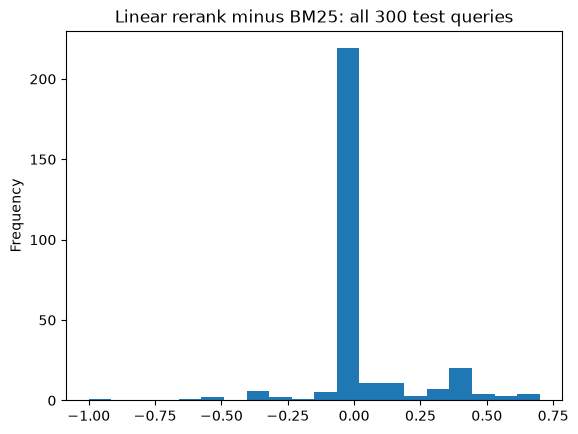

In [2]:
rows=[]
for r in ctx['per_query']:
    a=r['metrics']['bm25']['ndcg@10']; b=r['metrics']['linear_rerank']['ndcg@10']
    rows.append({'qid':r['qid'],'bm25':a,'linear':b,'delta':b-a})
errors=pd.DataFrame(rows)
print('300 queries: wins/ties/losses',int((errors.delta>1e-10).sum()),int((errors.delta.abs()<=1e-10).sum()),int((errors.delta < -1e-10).sum()))
display(errors.sort_values('delta').head(8))
errors.delta.plot.hist(bins=20,title='Linear rerank minus BM25: all 300 test queries');plt.show()

## 2. 候选丢失还是排序降位

对TinyBERT退化最严重的固定8个查询，重新计算同一个融合前20。目标根本不在20内是候选召回失败；在20内但掉出前10是排序问题；即使二者都发生，也应逐正例判断。对于多正例查询，下面用“至少一个相关是否还在候选/前10”作粗分类，不把它当细粒度归因。

In [3]:
failure_ids=[r['qid'] for r in ctx['result']['failures']]
failure_vectors=query_vectors(failure_ids); diagnostics=[]
by_id={r['qid']:r for r in ctx['per_query']}
for q,v in zip(failure_ids,failure_vectors):
    candidates=topk(score_query(q,v)[2],20); truth=ctx['truth']['test'][q]
    diagnostics.append({'qid':q,'relevant_in_candidates20':len(set(candidates)&truth), 'known_relevant':len(truth),
                        'hybrid_ndcg10':by_id[q]['metrics']['hybrid_rrf']['ndcg@10'],
                        'tinybert_ndcg10':by_id[q]['metrics']['tinybert_rerank']['ndcg@10']})
display(pd.DataFrame(diagnostics))
print('Local ctx contains query text for inspection; raw text is not saved to Git.')

/Users/lynnlee/Documents/Codex/2026-10-30/task/soutui-lab/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,qid,relevant_in_candidates20,known_relevant,hybrid_ndcg10,tinybert_ndcg10
0,1363,1,1,0.333333,0.000000
1,659,1,1,1.000000,0.000000
2,660,1,1,0.315465,0.000000
3,70,2,2,0.624051,0.000000
4,94,1,1,1.000000,0.000000
5,785,1,1,0.000000,0.000000
6,743,1,1,0.630930,0.386853
7,124,1,1,1.000000,0.430677


Local ctx contains query text for inspection; raw text is not saved to Git.


## 3. 先写计时边界，再报数字

正式表格含查询tokenization/编码、检索、融合和重排；不含模型加载、建索引、磁盘和HTTP。第4章只测索引，API返回的计时与HTTP客户端墙钟也不完全相同。对相同warm查询重复5次只是抖动观察，不能当容量测试或生产QPS。

接下来调用既有18580服务，不启动第二个服务器、不接管Jupyter；若未运行，按README先运行`./lab.sh up`。

In [4]:
import json, time, urllib.request
base='http://127.0.0.1:18580'
def call_search(query,method):
    request=urllib.request.Request(base+'/api/search',data=json.dumps({'query':query,'method':method,'limit':10}).encode(),headers={'Content-Type':'application/json'})
    with urllib.request.urlopen(request,timeout=90) as response: return json.load(response)
qid=ctx['per_query'][0]['qid']; query=ctx['queries'][qid]
call_search(query,'hybrid_rrf')  # explicit warmup, not included below
latency=[]
for _ in range(5):
    start=time.perf_counter(); answer=call_search(query,'hybrid_rrf'); wall=(time.perf_counter()-start)*1000
    latency.append({'http_wall_ms':wall,'reported_search_ms':answer['latency_ms']})
display(pd.DataFrame(latency))

,http_wall_ms,reported_search_ms
0,18.029292,11.091667
1,16.898375,11.355250
2,17.979375,11.189958
3,16.962208,10.923458
4,16.424583,10.975125


## 4. API与离线逐文档核验

同一个run_id、同一查询、同一方法，前10文档ID应逐项一致。质量分数接近不足以证明服务加载了正确模型。任意新查询没有qrels，因此服务只返回文档和排序分数，不显示虚构NDCG。

In [5]:
expected=by_id[qid]
checks=[]
for method in ['bm25','dense','hybrid_rrf','linear_rerank','tinybert_rerank']:
    response=call_search(query,method)
    ids=[x['document_id'] for x in response['items']]
    assert response['run_id']==ctx['receipt']['run_id']
    assert ids==expected['top10'][method]
    checks.append({'method':method,'documents':len(ids),'matches_offline':True})
display(pd.DataFrame(checks))

,method,documents,matches_offline
0,bm25,10,True
1,dense,10,True
2,hybrid_rrf,10,True
3,linear_rerank,10,True
4,tinybert_rerank,10,True


## 5. 从搜索推广到同一搜推广告系统

共用的是实验身份/来源与SHA、结果目录、稳定排序、服务与教学入口；不共用不相容的业务标签。推荐未交互不是真负曝光，搜索未判断不是真不相关，广告CTR不是搜索相关概率。拍卖收入必须与真实点击预测的评估分开，模拟结果不能冒充业务收益。

**下一轮实验卡片**：问题是什么？只改哪个变量？使用哪些训练/选择/审计查询？固定哪些预算？哪项失败会推翻假设？每次正式运行走`begin/finish`创建新记录，不能覆盖旧结果。第17章保留作为已完成实验总览，本六章的探索不会悄悄替换服务。

**练习**：选择一个退化查询，在本机查看真实文本与候选标题，提出可被验证的截断/领域假设；写出所需新评估数据，先记录计划，再训练。不要仅凭个例编造改善原因。